# Part (b): Text preprocessing

Each preprocessing step for text removes some variation and can remove topic information with it. This chapter measures what each step changes in the AG News articles audited in the [text EDA chapter](03_text_eda.ipynb), and whether the change helps a topic classifier. Every comparison uses the same training articles, the same cross-validation folds, and the same classifier settings, so differences between variants come from the preprocessing alone.

The chapter covers six techniques in the assignment's order: a normalization pipeline, four tokenization strategies, stop-word removal, stemming and lemmatization, three vector representations, and, as the advanced extension, pretrained Sentence Transformer embeddings. A final section scores the pipelines chosen by cross-validation once on the published test split.

## Load the environment

The setup cell imports the shared paths, the seed, and the helpers in `preprocessing.text_preprocessing`, downloads the NLTK resources used below into `RAW_DATA_DIR / "nltk_data"`, and records the package versions behind every result. The NLTK data index is not versioned, so the resource names are printed with the output. The Sentence Transformer section requires the `embeddings` extra described in the repository README.

In [1]:
import os
import platform
import time
from collections import Counter
from importlib.metadata import version
from itertools import chain

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk.tokenize import sent_tokenize, word_tokenize
from scipy.stats import mannwhitneyu
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, f1_score, accuracy_score, silhouette_score
from sklearn.metrics.pairwise import paired_cosine_distances
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

from preprocessing import RAW_DATA_DIR, RANDOM_STATE
from preprocessing.ag_news import AG_NEWS_DATASET, AG_NEWS_REVISION, load_ag_news, nearest_train_similarity
from preprocessing.text import rank_biserial
from preprocessing.text_preprocessing import (
    NORMALIZATION_STEPS, MeanWordVectors, collision_rates, normalize, oov_rate,
    presence_mutual_information, remove_wire_tags, sample_label_pairs, sparsity,
    stratified_sample, vocabulary_change,
)

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 200)
N_JOBS = min(5, os.cpu_count() or 1)
notebook_start = time.perf_counter()

# NLTK resources are versioned with the NLTK data index, not pinned; the list is
# printed so a rerun can be checked against it.
NLTK_DATA_DIR = RAW_DATA_DIR / "nltk_data"
NLTK_RESOURCES = ["punkt_tab", "stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng"]
nltk.data.path.insert(0, str(NLTK_DATA_DIR))
downloaded = {name: nltk.download(name, download_dir=str(NLTK_DATA_DIR), quiet=True) for name in NLTK_RESOURCES}
assert all(downloaded.values()), downloaded

package_versions = {
    name: version(name)
    for name in [
        "numpy", "pandas", "scikit-learn", "scipy", "nltk", "tokenizers", "gensim",
        "sentence-transformers", "torch", "datasets", "beautifulsoup4",
    ]
}
package_versions["python"] = platform.python_version()
print(f"Random seed: {RANDOM_STATE}; parallel jobs: {N_JOBS}")
print(f"NLTK resources in {NLTK_DATA_DIR}: {', '.join(NLTK_RESOURCES)}")
display(pd.Series(package_versions, name="version").to_frame())

Random seed: 42; parallel jobs: 5
NLTK resources in D:\HCMUS\DataMining\preprocessing\data\raw\nltk_data: punkt_tab, stopwords, wordnet, omw-1.4, averaged_perceptron_tagger_eng


,version
numpy,2.5.5
pandas,3.1.1
scikit-learn,1.9.1
scipy,1.18.1
nltk,3.10.4
tokenizers,0.23.3
gensim,4.4.0
sentence-transformers,6.3.0
torch,2.15.0+cpu
datasets,5.2.0


## Prepare data and the evaluation protocol

`load_ag_news` reads the Hugging Face dataset `fancyzhx/ag_news` at the pinned revision used in the EDA chapter. The samples are drawn with one generator seeded by `RANDOM_STATE`:

| Name | Articles | Drawn from | Used for |
|---|---|---|---|
| `train` | 120,000 | published training split | normalization statistics, tokenizer vocabularies, nearest-neighbor search |
| `cv_subset` | 30,000 (7,500 per topic) | `train` | every cross-validated comparison and every fitted representation |
| `probe` | 2,000 (500 per topic) | `train`, disjoint from `cv_subset` | cosine similarity, silhouette, t-SNE, and K-Means |
| `st_subset` | 8,000 (2,000 per topic) | `cv_subset` | the Sentence Transformer comparison |
| `test` | 7,600 | published test split | tokenizer OOV rates and the final evaluation only |

Cross-validated comparisons use the 30,000-article subset rather than all 120,000 articles to keep the book's execution time within the CI budget; the trigram TF-IDF model alone takes about two minutes per five folds on the full split. The subset lowers absolute scores slightly, but every variant is scored on the same five folds (`StratifiedKFold`, shuffled with `RANDOM_STATE`), so the paired difference between two variants on the same fold is the quantity that matters. The `compare` helper reports, for each variant, the mean and standard deviation of fold macro-F1, the mean accuracy, the mean paired difference from a stated baseline, the standard deviation of that difference, and the number of folds on which the variant is better.

Macro-F1 averages the per-topic $F_1 = 2PR/(P+R)$, where $P$ is precision and $R$ recall, with equal weight per topic. The four topics are balanced, so macro-F1 and accuracy track each other closely; macro-F1 is the primary metric. Deterministic text steps such as normalization and stemming learn nothing from the data and are applied before splitting. Everything with fitted state, including vectorizer vocabularies, IDF weights, BPE merges, Word2Vec vectors, and SVD components, is fitted inside `cross_validate` on the training folds or on `cv_subset`, never on the article being scored. The published test split is read only for tokenizer OOV, which the assignment defines on the test set, and for one final evaluation of pipelines fixed beforehand.

The selection rule for the final pipeline is fixed here, before any result is seen: at each decision, the simpler option is kept unless the candidate's mean paired gain in macro-F1 exceeds the standard deviation of that gain across folds.

In [2]:
train_raw, test_raw, label_names = load_ag_news()
LABEL_ORDER = list(label_names)
train = train_raw.assign(topic=pd.Categorical(train_raw["label"].map(dict(enumerate(LABEL_ORDER))), categories=LABEL_ORDER))
test = test_raw.assign(topic=pd.Categorical(test_raw["label"].map(dict(enumerate(LABEL_ORDER))), categories=LABEL_ORDER))

CV_PER_TOPIC, PROBE_PER_TOPIC, ST_PER_TOPIC = 7_500, 500, 2_000
rng = np.random.default_rng(RANDOM_STATE)
cv_subset = stratified_sample(train, "label", CV_PER_TOPIC, rng)
probe = stratified_sample(train, "label", PROBE_PER_TOPIC, rng, exclude=cv_subset.index)
st_subset = stratified_sample(cv_subset, "label", ST_PER_TOPIC, rng)
assert cv_subset.index.intersection(probe.index).empty
assert st_subset.index.isin(cv_subset.index).all()

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
st_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_cv, y_probe, y_st, y_test = (frame["label"].to_numpy() for frame in (cv_subset, probe, st_subset, test))

sample_sizes = pd.DataFrame(
    {
        name: frame["topic"].value_counts().reindex(LABEL_ORDER)
        for name, frame in [("train", train), ("cv_subset", cv_subset), ("probe", probe), ("st_subset", st_subset), ("test", test)]
    }
)
sample_sizes.loc["total"] = sample_sizes.sum()
print(f"Dataset: {AG_NEWS_DATASET} at revision {AG_NEWS_REVISION}")
display(sample_sizes)

D:\HCMUS\DataMining\preprocessing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: fancyzhx/ag_news at revision eb185aade064a813bc0b7f42de02595523103ca4


,train,cv_subset,probe,st_subset,test
topic,,,,,
World,30000,7500,500,2000,1900
Sports,30000,7500,500,2000,1900
Business,30000,7500,500,2000,1900
Sci/Tech,30000,7500,500,2000,1900
total,120000,30000,2000,8000,7600


In [3]:
SCORING = {"macro_f1": "f1_macro", "accuracy": "accuracy"}


def cv_scores(estimator, X, y=y_cv, cv=folds):
    # Every learned step (vectorizer, Word2Vec, classifier) sits inside the
    # estimator, so cross_validate refits it on each training fold.
    result = cross_validate(estimator, X, y, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
    return pd.DataFrame(
        {"macro_f1": result["test_macro_f1"], "accuracy": result["test_accuracy"]},
        index=pd.RangeIndex(1, cv.get_n_splits() + 1, name="fold"),
    )


def compare(scores, baseline):
    # Paired comparison: every variant is scored on the same folds, so the
    # per-fold difference removes fold-to-fold difficulty.
    base = scores[baseline]["macro_f1"]
    rows = {}
    for name, frame in scores.items():
        diff = frame["macro_f1"] - base
        rows[name] = {
            "macro_f1_mean": frame["macro_f1"].mean(),
            "macro_f1_std": frame["macro_f1"].std(ddof=1),
            "accuracy_mean": frame["accuracy"].mean(),
            "diff_vs_baseline": diff.mean(),
            "diff_std": diff.std(ddof=1),
            "folds_better": int((diff > 0).sum()),
        }
    return pd.DataFrame(rows).T


def prefer(simple, candidate):
    # Selection rule used for the final pipeline: keep the simpler option unless
    # the candidate's mean paired gain exceeds the fold standard deviation of
    # that gain.
    diff = SCORES_BY_NAME[candidate]["macro_f1"] - SCORES_BY_NAME[simple]["macro_f1"]
    return candidate if diff.mean() > diff.std(ddof=1) else simple


SCORES_BY_NAME = {}


def whitespace_tfidf(**kwargs):
    # One token convention for all text-level ablations: split on whitespace, no
    # further case folding, so differences come from the text, not the vectorizer.
    return TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, **kwargs)


def logistic_regression():
    return LogisticRegression(max_iter=1000)

## Measure normalization effects

Normalization maps different spellings of the same content to one form. The EDA found that AG News carries web-scraping residue: entities whose `&` was replaced by a space (` #39;s`, ` quot;`, `AT amp;T`), escaped HTML links that become long runs of link fragments, and literal backslashes joining two words. The pipeline in `preprocessing.text_preprocessing` applies eight steps in order:

1. Repair entities: restore the missing `&` of numeric entities and of `quot;`, `lt;`, `gt;`, and `amp;`, absorbing the space that replaced it, then decode HTML entities repeatedly until nothing changes. `#39;` becomes an apostrophe, `#36;` a dollar sign, and `&amp;lt;b&amp;gt;` becomes `<b>`.
2. Strip HTML: remove tags with BeautifulSoup and keep their text, so a link keeps its anchor text and loses its address.
3. Split backslashes: replace `\` with a space, so `Friday\but` becomes two words.
4. Remove URLs: delete `http(s)://` and `www.` addresses up to the next whitespace.
5. Mentions and hashtags: delete `@name`; keep the word of a `#tag` without the `#`. The EDA found almost none of either, so this step is implemented for completeness and is expected to change little.
6. Lowercase: Unicode case folding.
7. Digits and symbols: replace every character other than letters, digits, apostrophes, and hyphens with a space; drop apostrophes and hyphens that are not between two letters or digits; then delete tokens that contain no letter. Numbers such as `2004` and `5%` disappear, while `mp3`, `3g`, `it's`, and `well-known` stay. Abbreviations with periods split into letters (`u.s.` becomes `u s`).
8. Collapse whitespace.

A separate optional step removes the wire-service tags `(Reuters)`, `(AP)`, and `(AFP)`. The EDA showed that their frequency differs strongly by topic, so they can act as a shortcut to the label; removing them is evaluated as its own variant instead of being part of the default pipeline.

Counting convention. Vocabulary and length after each step use whitespace-separated pieces of the text, case-sensitive, so every change a step makes is visible in the counts. For consecutive steps with vocabularies $V_{\text{before}}$ and $V_{\text{after}}$, the removed share is $|V_{\text{before}} \setminus V_{\text{after}}| / |V_{\text{before}}|$ and the new share is $|V_{\text{after}} \setminus V_{\text{before}}| / |V_{\text{before}}|$; both use the earlier vocabulary as the denominator. The documents-changed share is the fraction of articles whose text the step alters.

Classification effect. Logistic regression on TF-IDF features is cross-validated on the text after each cumulative step and on the full pipeline without wire tags. The vectorizer splits on whitespace and does not lowercase, so the text, not the vectorizer, determines the tokens.

Normalization of 120,000 training and 7,600 test articles took 30 s


,types,words_mean,words_median,chars_mean,types_removed_share,types_new_share,docs_changed_share,types_vs_raw
step,,,,,,,,
raw,188110,37.8474,37.0,236.4775,NaN,NaN,NaN,1.0000
repair entities,192458,37.4544,37.0,233.7832,0.0413,0.0644,0.3221,1.0231
strip HTML,190903,37.4008,37.0,231.3156,0.0118,0.0037,0.0437,1.0148
split backslashes,178967,37.5217,37.0,231.3156,0.0766,0.0140,0.1084,0.9514
remove URLs,178901,37.5213,37.0,231.3030,0.0004,0.0000,0.0006,0.9510
mentions and hashtags,178901,37.5213,37.0,231.3030,0.0000,0.0000,0.0000,0.9510
lowercase,149061,37.5213,37.0,231.3030,0.5011,0.3343,1.0000,0.7924
digits and symbols,83282,36.5804,36.0,230.3070,0.4940,0.0527,0.9964,0.4427
collapse whitespace,83282,36.5804,36.0,222.9610,0.0000,0.0000,0.9997,0.4427


Whitespace word count quantiles, training split:


,raw,normalized
0.01,18.0,18.0
0.25,32.0,31.0
0.50,37.0,36.0
0.75,43.0,41.0
0.99,70.0,68.0


,mean_word_change,median_word_change,share_shorter
topic,,,
World,-1.088,-1.0,0.662
Sports,-1.757,-1.0,0.782
Business,-1.286,-1.0,0.661
Sci/Tech,-0.937,-1.0,0.546


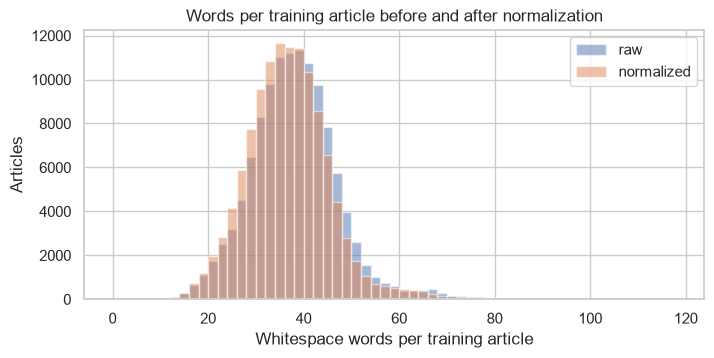

In [4]:
step_start = time.perf_counter()
stages = {"raw": train["text"]}
for name, step in NORMALIZATION_STEPS:
    stages[name] = list(stages.values())[-1].map(step)
train_norm = stages[NORMALIZATION_STEPS[-1][0]]
test_norm = test["text"].map(normalize)
assert train_norm.str.len().gt(0).all() and test_norm.str.len().gt(0).all()


def whitespace_vocabulary(texts):
    return set(chain.from_iterable(texts.str.split()))


rows, previous_name, previous_vocab = [], None, None
for name, texts in stages.items():
    vocab = whitespace_vocabulary(texts)
    words = texts.str.split().str.len()
    row = {
        "step": name,
        "types": len(vocab),
        "words_mean": words.mean(),
        "words_median": words.median(),
        "chars_mean": texts.str.len().mean(),
    }
    if previous_vocab is not None:
        change = vocabulary_change(previous_vocab, vocab)
        row |= {
            "types_removed_share": change["removed_share"],
            "types_new_share": change["new_share"],
            "docs_changed_share": (texts != stages[previous_name]).mean(),
        }
    rows.append(row)
    previous_name, previous_vocab = name, vocab
normalization_effects = pd.DataFrame(rows).set_index("step")
normalization_effects["types_vs_raw"] = normalization_effects["types"] / normalization_effects.loc["raw", "types"]

raw_words = stages["raw"].str.split().str.len()
norm_words = train_norm.str.split().str.len()
length_quantiles = pd.DataFrame(
    {"raw": raw_words.quantile([0.01, 0.25, 0.5, 0.75, 0.99]), "normalized": norm_words.quantile([0.01, 0.25, 0.5, 0.75, 0.99])}
)
word_change = norm_words - raw_words
length_change_by_topic = word_change.groupby(train["topic"], observed=True).agg(["mean", "median", lambda s: (s < 0).mean()])
length_change_by_topic.columns = ["mean_word_change", "median_word_change", "share_shorter"]

print(f"Normalization of {len(train):,} training and {len(test):,} test articles took {time.perf_counter() - step_start:.0f} s")
display(normalization_effects.round(4))
print("Whitespace word count quantiles, training split:")
display(length_quantiles)
display(length_change_by_topic.round(3))

fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 120, 2)
ax.hist(raw_words, bins=bins, alpha=0.5, label="raw")
ax.hist(norm_words, bins=bins, alpha=0.5, label="normalized")
ax.set_title("Words per training article before and after normalization")
ax.set_xlabel("Whitespace words per training article")
ax.set_ylabel("Articles")
ax.legend()
plt.show()

In [5]:
EXAMPLE_POSITIONS = [1, 5, 9, 2000]
examples = pd.DataFrame(
    {"raw": stages["raw"].iloc[EXAMPLE_POSITIONS].str.slice(0, 180), "normalized": train_norm.iloc[EXAMPLE_POSITIONS].str.slice(0, 180)}
)
escaped_link = stages["raw"].str.contains("&lt;A HREF", regex=False)
examples.loc["escaped link"] = [stages["raw"][escaped_link].iloc[0][:260], train_norm[escaped_link].iloc[0][:260]]
display(examples)

,raw,normalized
1,"Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial pla",carlyle looks toward commercial aerospace reuters reuters private investment firm carlyle group which has a reputation for making well-timed and occasionally controversial plays in
5,"Stocks End Up, But Near Year Lows (Reuters) Reuters - Stocks ended slightly higher on Friday\but stayed near lows for the year as oil prices surged past #36;46\a barrel, offsettin",stocks end up but near year lows reuters reuters stocks ended slightly higher on friday but stayed near lows for the year as oil prices surged past a barrel offsetting a positive o
9,"Wall St. Bears Claw Back Into the Black NEW YORK (Reuters) - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.",wall st bears claw back into the black new york reuters short-sellers wall street's dwindling band of ultra-cynics are seeing green again
2000,"Applied Materials Reports Profit in 3Q Applied Materials Inc., the world #39;s largest supplier of machines that make computer chips, Tuesday said surging sales in its latest quart",applied materials reports profit in 3q applied materials inc the world's largest supplier of machines that make computer chips tuesday said surging sales in its latest quarter surp
escaped link,"KMart Posts Profit; Cash Hits \$2.6 Bln CHICAGO (Reuters) - Kmart Holdings Corp. &lt;A HREF=""http://www.investor.reuters.com/FullQuote.aspx?ticker=KMRT.O target=/stocks/quickinfo/fullquote""&gt;KM...",kmart posts profit cash hits bln chicago reuters kmart holdings corp kmrt o on monday reported its third consecutive quarterly profit and boosted its cash pile to billion as it cut spending on adv...


In [6]:
step_start = time.perf_counter()
NORMALIZATION_VARIANTS = {
    "raw": "raw",
    "markup cleanup (steps 1-5)": "mentions and hashtags",
    "markup cleanup + lowercase": "lowercase",
    "full pipeline": "collapse whitespace",
}
cv_texts = {name: stages[stage].loc[cv_subset.index] for name, stage in NORMALIZATION_VARIANTS.items()}
cv_texts["full pipeline, wire tags removed"] = cv_subset["text"].map(remove_wire_tags).map(normalize)
for name, texts in cv_texts.items():
    SCORES_BY_NAME[f"norm: {name}"] = cv_scores(make_pipeline(whitespace_tfidf(), logistic_regression()), texts)
normalization_cv = compare({name: SCORES_BY_NAME[f"norm: {name}"] for name in cv_texts}, "raw")
print(f"TF-IDF + logistic regression, 5-fold CV on {len(cv_subset):,} articles ({time.perf_counter() - step_start:.0f} s)")
display(normalization_cv.round(4))

TF-IDF + logistic regression, 5-fold CV on 30,000 articles (35 s)


,macro_f1_mean,macro_f1_std,accuracy_mean,diff_vs_baseline,diff_std,folds_better
raw,0.8936,0.0022,0.8940,0.0000,0.0000,0.0
markup cleanup (steps 1-5),0.8922,0.0023,0.8925,-0.0015,0.0005,0.0
markup cleanup + lowercase,0.8954,0.0031,0.8957,0.0018,0.0014,4.0
full pipeline,0.9009,0.0033,0.9012,0.0072,0.0017,5.0
"full pipeline, wire tags removed",0.8978,0.0029,0.8981,0.0042,0.0015,5.0


The pipeline shrinks the training vocabulary from {eval}`f"{int(normalization_effects.loc['raw', 'types']):,}"` to {eval}`f"{int(normalization_effects.loc['collapse whitespace', 'types']):,}"` whitespace types ({eval}`f"{normalization_effects.loc['collapse whitespace', 'types_vs_raw']:.0%}"` of the raw count), while the median article loses one word (`length_quantiles`). Two steps do most of the merging. Lowercasing removes {eval}`f"{normalization_effects.loc['lowercase', 'types_removed_share']:.0%}"` of the types it receives, because `Oil`, `OIL`, and `oil` become one type. The digit and symbol step removes another {eval}`f"{normalization_effects.loc['digits and symbols', 'types_removed_share']:.0%}"`: punctuation no longer sticks to words (`said,` and `said.` become `said`), and numbers, which are mostly unique prices, scores, and dates, disappear.

The markup steps change many articles but few types. Entity repair alters {eval}`f"{normalization_effects.loc['repair entities', 'docs_changed_share']:.0%}"` of articles and is the only step that adds more types than it removes ({eval}`f"{normalization_effects.loc['repair entities', 'types_new_share']:.1%}"` new against {eval}`f"{normalization_effects.loc['repair entities', 'types_removed_share']:.1%}"` removed): ` #39;s` becomes a possessive attached to its word, so `world's` and `company's` appear as types of their own. Splitting backslashes removes {eval}`f"{normalization_effects.loc['split backslashes', 'types_removed_share']:.1%}"` of types, the glued pairs such as `Friday\but`. URL removal touches {eval}`f"{normalization_effects.loc['remove URLs', 'docs_changed_share']:.2%}"` of articles, and the mention and hashtag step changes {eval}`f"{normalization_effects.loc['mentions and hashtags', 'docs_changed_share']:.2%}"`, as the EDA predicted. Sports articles lose the most words on average ({eval}`f"{length_change_by_topic.loc['Sports', 'mean_word_change']:.2f}"` against {eval}`f"{length_change_by_topic.loc['Sci/Tech', 'mean_word_change']:.2f}"` for Sci/Tech), consistent with scores and times being removed as numbers.

For classification, the full pipeline raises cross-validated macro-F1 by {eval}`f"{normalization_cv.loc['full pipeline', 'diff_vs_baseline']:+.4f}"` over raw text, with a fold standard deviation of the gain of {eval}`f"{normalization_cv.loc['full pipeline', 'diff_std']:.4f}"`, better on {eval}`int(normalization_cv.loc['full pipeline', 'folds_better'])` of 5 folds. The gain comes from lowercasing and the digit and symbol step, which pool counts of the same word. Markup cleanup alone changes macro-F1 by {eval}`f"{normalization_cv.loc['markup cleanup (steps 1-5)', 'diff_vs_baseline']:+.4f}"` ({eval}`int(normalization_cv.loc['markup cleanup (steps 1-5)', 'folds_better'])` of 5 folds better). Removing residue is therefore not automatically an improvement for the classifier: the EDA found escaped stock-quote links almost only in Business and Sci/Tech articles, so their fragments act as weak topic cues. Cleanup is still kept because it makes every later count describe words rather than encoding artifacts, and its cost is small next to the gain of the full pipeline.

Removing the Reuters, AP, and AFP tags and datelines lowers macro-F1 by {eval}`f"{normalization_cv.loc['full pipeline', 'macro_f1_mean'] - normalization_cv.loc['full pipeline, wire tags removed', 'macro_f1_mean']:.4f}"` relative to the full pipeline. The source shortcut that the EDA identified is real: the classifier uses the agency as evidence of the topic. It is also small next to the topic vocabulary, since the pipeline without the markers still beats raw text by {eval}`f"{normalization_cv.loc['full pipeline, wire tags removed', 'diff_vs_baseline']:+.4f}"`. The selection rule keeps the markers because removing them costs score on AG News. For articles from other sources, where the agency carries no topic information, the score without markers is the more realistic estimate.

## Compare four tokenization strategies

A tokenizer decides the unit that every later count refers to. Smaller units make unseen units rarer but produce longer sequences and units that carry less meaning on their own. The four strategies compared are:

- Word level: NLTK `word_tokenize` with the Penn Treebank rules, which split punctuation and clitics (`company's` becomes `company` and `'s`).
- Sentence level: NLTK's pretrained Punkt model, which splits text at sentence boundaries; each sentence is one unit.
- Character level: every Unicode code point is a unit.
- Subword: byte-pair encoding (BPE; Sennrich et al., 2016) from the Hugging Face `tokenizers` library. BPE starts from characters and repeatedly merges the most frequent adjacent pair until the vocabulary reaches `BPE_VOCAB_SIZE` = 30,000 entries. Text is first split on whitespace and punctuation; a character never seen in training becomes `[UNK]`.

Input. Sentence boundaries depend on punctuation and capitalization, which normalization steps 6 and 7 remove. All four tokenizers therefore read the cleaned text after steps 1 to 5 and whitespace collapsing: markup is gone, but case and punctuation remain, so units are case-sensitive and `Oil` and `oil` count as different words. Vocabularies and BPE merges are learned from the 120,000 training articles only.

For each strategy the OOV rate on the test split is

$$
\mathrm{OOV}_{\text{token}} = \frac{N_{\text{unknown}}}{N_{\text{tokens}}}, \qquad \mathrm{OOV}_{\text{type}} = \frac{|T_{\text{test}} \setminus V_{\text{train}}|}{|T_{\text{test}}|},
$$

where $N_{\text{tokens}}$ is the number of units in all test articles, $N_{\text{unknown}}$ the number of those units absent from the training vocabulary $V_{\text{train}}$, and $T_{\text{test}}$ the set of distinct test units. For BPE, the unknown units are `[UNK]` tokens. A second word-level row keeps only words seen at least twice in training, the kind of frequency cutoff a vectorizer with `min_df=2` applies. The fertility of BPE is the mean number of subword pieces per pre-tokenized word.

In [7]:
step_start = time.perf_counter()
# Tokenizers need punctuation and case for sentence boundaries, so they read the
# text after markup cleanup but before lowercasing and symbol removal.
CLEANUP_STEPS = NORMALIZATION_STEPS[:5] + [NORMALIZATION_STEPS[-1]]
train_clean = train["text"].map(lambda text: normalize(text, CLEANUP_STEPS))
test_clean = test["text"].map(lambda text: normalize(text, CLEANUP_STEPS))

tokenized = {}
tokenized["word (NLTK)"] = [[word_tokenize(text, preserve_line=True) for text in split] for split in (train_clean, test_clean)]
tokenized["sentence (NLTK Punkt)"] = [[sent_tokenize(text) for text in split] for split in (train_clean, test_clean)]

BPE_VOCAB_SIZE = 30_000
bpe = Tokenizer(models.BPE(unk_token="[UNK]"))
bpe.pre_tokenizer = pre_tokenizers.Whitespace()
bpe.train_from_iterator(train_clean.tolist(), trainers.BpeTrainer(vocab_size=BPE_VOCAB_SIZE, special_tokens=["[UNK]"], show_progress=False))
tokenized["subword (BPE)"] = [[encoding.tokens for encoding in bpe.encode_batch(split.tolist())] for split in (train_clean, test_clean)]

word_counts = Counter(chain.from_iterable(tokenized["word (NLTK)"][0]))
vocabularies = {
    "word (NLTK)": set(word_counts),
    "word (NLTK), train frequency >= 2": {word for word, count in word_counts.items() if count >= 2},
    "sentence (NLTK Punkt)": set(chain.from_iterable(tokenized["sentence (NLTK Punkt)"][0])),
    "character": set("".join(train_clean)),
    # [UNK] is a vocabulary entry but marks an unknown unit, so it counts as OOV.
    "subword (BPE)": set(bpe.get_vocab()) - {"[UNK]"},
}
rows = {}
# Character units are the code points of each string, counted without
# materializing one list per training article.
tokenized["character"] = [None, [list(text) for text in test_clean]]
for name, vocab in vocabularies.items():
    train_docs, test_docs = tokenized[name.split(",")[0]]
    rates = oov_rate(vocab, test_docs)
    rows[name] = {
        "vocabulary_size": len(vocab),
        "mean_units_train": train_clean.str.len().mean() if train_docs is None else np.mean([len(doc) for doc in train_docs]),
        "mean_units_test": np.mean([len(doc) for doc in test_docs]),
        "test_oov_token_rate": rates["token_rate"],
        "test_oov_type_rate": rates["type_rate"],
        "test_units": int(rates["test_units"]),
    }
tokenization_comparison = pd.DataFrame(rows).T
empty_documents = {name: sum(len(doc) == 0 for doc in docs[1]) for name, docs in tokenized.items()}
assert not any(empty_documents.values()), empty_documents

pre_words = [len(bpe.pre_tokenizer.pre_tokenize_str(text)) for text in test_clean]
bpe_fertility = sum(len(doc) for doc in tokenized["subword (BPE)"][1]) / sum(pre_words)
word_oov_examples = Counter(token for doc in tokenized["word (NLTK)"][1] for token in doc if token not in vocabularies["word (NLTK)"]).most_common(15)
print(f"Tokenization took {time.perf_counter() - step_start:.0f} s")
display(tokenization_comparison.round(4))
print(f"BPE fertility on test: {bpe_fertility:.3f} subword pieces per pre-tokenized word")
print("Most frequent test word tokens missing from the training vocabulary:", word_oov_examples)
example_text = test_clean.iloc[0][:120]
display(pd.Series({name: str(docs[1][0][:12]) for name, docs in tokenized.items()}, name=example_text).to_frame())

Tokenization took 48 s


,vocabulary_size,mean_units_train,mean_units_test,test_oov_token_rate,test_oov_type_rate,test_units
word (NLTK),119572.0,41.4923,41.3308,0.0112,0.1039,314114.0
"word (NLTK), train frequency >= 2",69231.0,41.4923,41.3308,0.0176,0.1619,314114.0
sentence (NLTK Punkt),155008.0,1.3269,1.3322,0.9611,0.9709,10125.0
character,104.0,230.6367,229.9571,0.0000,0.0000,1747674.0
subword (BPE),29999.0,46.4422,46.4003,0.0000,0.0000,352642.0


BPE fertility on test: 1.051 subword pieces per pre-tokenized word
Most frequent test word tokens missing from the training vocabulary: [('PGP', 4), ('Zeile', 4), ('551m', 4), ('Wildfires', 3), ('Shoppach', 3), ('Baggaley', 3), ('Moonves', 3), ('pint', 3), ('NetManage', 3), ('JGB', 3), ('refuellers', 3), ('Lokomotiv', 3), ('planter', 3), ('Akash', 3), ('Flat-screen', 3)]


,Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks w
word (NLTK),"['Fears', 'for', 'T', 'N', 'pension', 'after', 'talks', 'Unions', 'representing', 'workers', 'at', 'Turner']"
sentence (NLTK Punkt),"[""Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.""]"
subword (BPE),"['Fears', 'for', 'T', 'N', 'pension', 'after', 'talks', 'Unions', 'representing', 'workers', 'at', 'Turner']"
character,"['F', 'e', 'a', 'r', 's', ' ', 'f', 'o', 'r', ' ', 'T', ' ']"


The four strategies trade vocabulary size against sequence length. Word tokens give a vocabulary of {eval}`f"{int(tokenization_comparison.loc['word (NLTK)', 'vocabulary_size']):,}"` types and {eval}`f"{tokenization_comparison.loc['word (NLTK)', 'mean_units_test']:.1f}"` tokens per test article, characters give {eval}`int(tokenization_comparison.loc['character', 'vocabulary_size'])` units and {eval}`f"{tokenization_comparison.loc['character', 'mean_units_test']:.0f}"` per article, and BPE sits between them with {eval}`f"{int(tokenization_comparison.loc['subword (BPE)', 'vocabulary_size']):,}"` subwords and {eval}`f"{tokenization_comparison.loc['subword (BPE)', 'mean_units_test']:.1f}"` per article.

The OOV rates are comparable only where the unit is the same. At word level, {eval}`f"{tokenization_comparison.loc['word (NLTK)', 'test_oov_token_rate']:.2%}"` of test tokens and {eval}`f"{tokenization_comparison.loc['word (NLTK)', 'test_oov_type_rate']:.1%}"` of test types are unseen in training. The gap between the two rates is Zipf's law from the EDA at work: unseen words are rare words, so they are many types but few tokens. The most frequent unseen tokens are names, product codes, and rare words (`word_oov_examples`). Keeping only words seen at least twice raises the token OOV rate to {eval}`f"{tokenization_comparison.loc['word (NLTK), train frequency >= 2', 'test_oov_token_rate']:.2%}"` while shrinking the vocabulary to {eval}`f"{tokenization_comparison.loc['word (NLTK), train frequency >= 2', 'vocabulary_size'] / tokenization_comparison.loc['word (NLTK)', 'vocabulary_size']:.0%}"` of its size, which is the trade a `min_df=2` vectorizer makes.

Character and BPE tokenization have no unknown units on this test split: every test character occurs somewhere in the training text, and BPE can always fall back to characters, so `[UNK]` never appears. A zero OOV rate does not mean the units are understood; a rare name becomes a sequence of short pieces. With a 30,000-entry vocabulary, BPE keeps most English words whole, at {eval}`f"{bpe_fertility:.3f}"` pieces per word, so on this corpus it behaves almost like a word tokenizer that never fails.

The sentence row measures something else. {eval}`f"{tokenization_comparison.loc['sentence (NLTK Punkt)', 'test_oov_token_rate']:.1%}"` of test sentences never occur in training, because a sentence is almost never repeated verbatim. Its complement, {eval}`f"{1 - tokenization_comparison.loc['sentence (NLTK Punkt)', 'test_oov_token_rate']:.1%}"`, is the share of test sentences copied from training text, which reflects the wire-story near-duplicates found in the EDA, not vocabulary coverage. Sentence units suit tasks that need sentence boundaries, such as summarization or sentence embeddings, and are not a vocabulary for a bag-of-units classifier. Articles average {eval}`f"{tokenization_comparison.loc['sentence (NLTK Punkt)', 'mean_units_test']:.2f}"` sentences, since most consist of a headline and a one-sentence description.

## Evaluate stop-word removal

Stop words are frequent function words such as `the`, `of`, and `is`. Removing them shrinks the vocabulary and the number of tokens. Whether it helps depends on how much topic information they carry, which the mutual information between a word and the label measures. For a term $w$ with presence indicator $X_w \in \{0, 1\}$ (the term occurs in the article at least once) and topic $C$,

$$
I(X_w; C) = \sum_{x \in \{0,1\}} \sum_{c} P(X_w = x, C = c) \log \frac{P(X_w = x, C = c)}{P(X_w = x)\,P(C = c)},
$$

in nats, with probabilities estimated as frequencies over the articles of `cv_subset` and $0 \log 0 = 0$. $I = 0$ means the term's presence is independent of the topic. `presence_mutual_information` computes this for every term at once from sparse counts.

The MI of a term does not depend on which other terms are in the vocabulary, so removal changes the mean MI only by changing which terms are averaged. The table reports the mean over all terms and over terms that occur in at least five articles, because MI estimates of very rare terms are dominated by chance. The stop-word list is NLTK's English list applied to the normalized, whitespace-tokenized text. The list contains negations (`not`, `no`, `nor`, and contracted forms such as `don't`), which matter for sentiment tasks; their MI with the topic is reported separately.

Classification effect. Multinomial Naive Bayes on raw counts, as the assignment requires, and logistic regression on TF-IDF, which the final pipeline uses, are each cross-validated with and without removal on the same folds.

In [8]:
step_start = time.perf_counter()
STOP_WORDS = sorted(set(stopwords.words("english")))
NEGATION_WORDS = [word for word in STOP_WORDS if word in {"no", "nor", "not"} or word.endswith("n't")]
cv_norm = train_norm.loc[cv_subset.index]


def count_vectorizer(**kwargs):
    return CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, **kwargs)


counts_all = count_vectorizer().fit(cv_norm)
X_all = counts_all.transform(cv_norm)
terms = counts_all.get_feature_names_out()
mi = pd.Series(presence_mutual_information(X_all, y_cv), index=terms)
doc_freq = pd.Series(np.asarray((X_all > 0).sum(axis=0)).ravel(), index=terms)
is_stop = mi.index.isin(STOP_WORDS)
frequent = doc_freq >= 5

stop_word_summary = pd.DataFrame(
    {
        "keep stop words": {
            "vocabulary_size": len(mi),
            "tokens": int(X_all.sum()),
            "mean_mi_all_terms": mi.mean(),
            "mean_mi_df_ge_5": mi[frequent].mean(),
        },
        "remove stop words": {
            "vocabulary_size": int((~is_stop).sum()),
            "tokens": int(X_all[:, ~is_stop].sum()),
            "mean_mi_all_terms": mi[~is_stop].mean(),
            "mean_mi_df_ge_5": mi[~is_stop & frequent].mean(),
        },
    }
).T
# Topic share among the articles that contain each term, to show which topic a
# high-MI stop word points to.
topic_counts = pd.DataFrame(
    (X_all > 0).astype(np.int64).T @ pd.get_dummies(cv_subset["topic"]).to_numpy(dtype=np.int64),
    index=terms, columns=LABEL_ORDER,
)
topic_share = topic_counts.div(topic_counts.sum(axis=1), axis=0)
stop_word_mi = pd.DataFrame(
    {"mi": mi[is_stop], "doc_freq": doc_freq[is_stop], "top_topic": topic_share[is_stop].idxmax(axis=1), "top_topic_share": topic_share[is_stop].max(axis=1)}
).sort_values("mi", ascending=False)
mi_rank_percentile = mi.rank(pct=True)
stop_word_mi["mi_percentile_in_vocabulary"] = mi_rank_percentile[stop_word_mi.index]

for name, words in [("keep stop words", None), ("remove stop words", STOP_WORDS)]:
    SCORES_BY_NAME[f"stop NB: {name}"] = cv_scores(make_pipeline(count_vectorizer(stop_words=words), MultinomialNB()), cv_norm)
    SCORES_BY_NAME[f"stop LR: {name}"] = cv_scores(make_pipeline(whitespace_tfidf(stop_words=words), logistic_regression()), cv_norm)
stop_word_cv = pd.concat(
    {
        "Multinomial NB (counts)": compare({n: SCORES_BY_NAME[f"stop NB: {n}"] for n in ["keep stop words", "remove stop words"]}, "keep stop words"),
        "Logistic regression (TF-IDF)": compare({n: SCORES_BY_NAME[f"stop LR: {n}"] for n in ["keep stop words", "remove stop words"]}, "keep stop words"),
    }
)
print(f"NLTK English stop words: {len(STOP_WORDS)}; negation words among them: {NEGATION_WORDS}")
print(f"Stop words present in the cv_subset vocabulary: {int(is_stop.sum())}; computed in {time.perf_counter() - step_start:.0f} s")
display(stop_word_summary.round(5))
print("Stop words with the highest presence-label mutual information (nats):")
display(stop_word_mi.head(10).round(5))
display(stop_word_mi.loc[stop_word_mi.index.intersection(NEGATION_WORDS)].round(5))
display(stop_word_cv.round(4))

NLTK English stop words: 198; negation words among them: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't", 'no', 'nor', 'not', "shan't", "shouldn't", "wasn't", "weren't", "won't", "wouldn't"]
Stop words present in the cv_subset vocabulary: 178; computed in 11 s


,vocabulary_size,tokens,mean_mi_all_terms,mean_mi_df_ge_5
keep stop words,45877.0,1097773.0,0.00025,0.00068
remove stop words,45699.0,743270.0,0.00024,0.00066


Stop words with the highest presence-label mutual information (nats):


,mi,doc_freq,top_topic,top_topic_share,mi_percentile_in_vocabulary
his,0.03390,2978,Sports,0.53492,0.99996
its,0.03309,4747,Business,0.42848,0.99991
he,0.01470,1667,Sports,0.51590,0.99911
in,0.01320,16071,World,0.30459,0.99889
s,0.01054,1867,Business,0.45420,0.99813
was,0.00970,3002,Sports,0.36775,0.99793
at,0.00783,5289,Sports,0.36283,0.99697
that,0.00776,6145,Sci/Tech,0.33247,0.99690
after,0.00722,3400,Sports,0.30794,0.99651
it,0.00698,4103,Sci/Tech,0.32732,0.99627


,mi,doc_freq,top_topic,top_topic_share,mi_percentile_in_vocabulary
no,0.00564,1223,Sports,0.48733,0.99503
didn't,0.00133,120,Sports,0.63333,0.96898
not,0.00093,1617,Sports,0.31787,0.95599
wasn't,0.00077,57,Sports,0.64912,0.94623
don't,0.00073,165,Sci/Tech,0.42424,0.94324
couldn't,0.00064,41,Sports,0.70732,0.93480
hasn't,0.00052,34,Sports,0.67647,0.92170
isn't,0.00045,87,Sci/Tech,0.39080,0.90943
doesn't,0.00038,116,Sci/Tech,0.35345,0.89696
weren't,0.00026,20,Sports,0.65000,0.85205


macro_f1_mean  macro_f1_std  \
Multinomial NB (counts)      keep stop words           0.8990        0.0025   
                             remove stop words         0.9014        0.0025   
Logistic regression (TF-IDF) keep stop words           0.9009        0.0033   
                             remove stop words         0.9027        0.0037   

                                                accuracy_mean  \
Multinomial NB (counts)      keep stop words           0.8993   
                             remove stop words         0.9017   
Logistic regression (TF-IDF) keep stop words           0.9012   
                             remove stop words         0.9030   

                                                diff_vs_baseline  diff_std  \
Multinomial NB (counts)      keep stop words              0.0000     0.000   
                             remove stop words            0.0024     0.001   
Logistic regression (TF-IDF) keep stop words              0.0000     0.000   
                             remove stop words            0.0018     0.003   

                                                folds_better  
Multinomial NB (counts)      keep stop words             0.0  
                             remove stop words           5.0  
Logistic regression (TF-IDF) keep stop words             0.0  
                             remove stop words           3.0

Removing the {eval}`len(STOP_WORDS)` NLTK stop words barely changes the vocabulary ({eval}`f"{int(stop_word_summary.loc['keep stop words', 'vocabulary_size']):,}"` to {eval}`f"{int(stop_word_summary.loc['remove stop words', 'vocabulary_size']):,}"` types) but removes {eval}`f"{1 - stop_word_summary.loc['remove stop words', 'tokens'] / stop_word_summary.loc['keep stop words', 'tokens']:.0%}"` of all tokens. Mean MI stays almost the same ({eval}`f"{stop_word_summary.loc['keep stop words', 'mean_mi_df_ge_5']:.5f}"` and {eval}`f"{stop_word_summary.loc['remove stop words', 'mean_mi_df_ge_5']:.5f}"` nats over terms in at least five articles), because {eval}`int(is_stop.sum())` terms hardly move an average over tens of thousands. The mean slightly falls rather than rises, which shows that stop words are not the least informative terms: rare content words are.

Several stop words carry clear topic information. `his`, `its`, and `he` rank above the 99.9th percentile of MI in the whole vocabulary (`stop_word_mi`): the `top_topic` column gives the topic in which articles containing the word are most frequent, and its share of those articles. `its` is most frequent in Business articles, about companies, and `his` and `he` in Sports articles, about players. Negations carry little topic information except `no`; `not` and the contracted forms sit lower in the MI ranking. Where they lean toward a topic it is mostly Sports, through quoted players (`didn't`, `couldn't`), not through any sense of negation. For topic classification the usual argument for keeping negations, which concerns sentiment, therefore does not apply.

Naive Bayes improves with removal by {eval}`f"{stop_word_cv.loc[('Multinomial NB (counts)', 'remove stop words'), 'diff_vs_baseline']:+.4f}"` macro-F1 on {eval}`int(stop_word_cv.loc[('Multinomial NB (counts)', 'remove stop words'), 'folds_better'])` of 5 folds. Multinomial NB adds one log-probability per token, so the {eval}`f"{1 - stop_word_summary.loc['remove stop words', 'tokens'] / stop_word_summary.loc['keep stop words', 'tokens']:.0%}"` of tokens that are nearly uniform across topics add noise to every article's score; removing them helps NB specifically. Logistic regression on TF-IDF changes by {eval}`f"{stop_word_cv.loc[('Logistic regression (TF-IDF)', 'remove stop words'), 'diff_vs_baseline']:+.4f}"` with a fold standard deviation of {eval}`f"{stop_word_cv.loc[('Logistic regression (TF-IDF)', 'remove stop words'), 'diff_std']:.4f}"`. IDF weighting already down-weights frequent words and the model learns a small weight for uninformative ones, so removal matters less. Stop-word removal therefore does not always improve results: the effect depends on the classifier, and the list removes some informative words.

## Compare stemming and lemmatization

Stemming and lemmatization map inflected forms to a common root so that `market` and `markets` count as one feature. Three methods are compared with an unchanged baseline:

- Porter stemmer (Porter, 1980): suffix-stripping rules applied in five phases; the root need not be a word (`company` becomes `compani`).
- Snowball stemmer for English, also called Porter2: a revised rule set that fixes several Porter errors.
- WordNet lemmatizer: looks up the dictionary form in WordNet for a given part of speech. Part-of-speech tags come from NLTK's averaged perceptron tagger run on each normalized article, mapped to WordNet's noun, verb, adjective, and adverb classes, with noun as the default. The normalized text is lowercase and has no punctuation, which lowers tagging accuracy; this is a limitation of applying the lemmatizer after normalization.

The collision rate measures how much a method merges. Let $T$ be the distinct alphabetic word types in the normalized `cv_subset` and $f$ the mapping from a type to its root. For WordNet, $f$ uses each type's most frequent tag. Then

$$
\text{collision rate} = \frac{\left|\{\, t \in T : \exists\, t' \in T,\ t' \neq t,\ f(t') = f(t) \,\}\right|}{|T|}, \qquad \text{reduction} = 1 - \frac{|f(T)|}{|T|}.
$$

The collision rate is the share of types that share their root with at least one other type, as the assignment defines it; the reduction is the relative shrinkage of the vocabulary. A token-weighted collision rate counts each type by its frequency. Collisions are not errors in themselves: `market` and `markets` should merge, `news` and `new` should not.

Classification effect. Logistic regression on TF-IDF is cross-validated on the stemmed or lemmatized text of each method. Stemming is deterministic, so applying it before splitting does not leak information; the vectorizer is still fitted inside each fold.

In [9]:
step_start = time.perf_counter()
cv_tokens = [text.split() for text in cv_norm]
type_counts = Counter(token for doc in cv_tokens for token in doc if token.isalpha())

porter, snowball, wordnet = PorterStemmer(), SnowballStemmer("english"), WordNetLemmatizer()
WORDNET_POS = {"J": "a", "V": "v", "N": "n", "R": "r"}
tagged = nltk.pos_tag_sents(cv_tokens)
tag_counts = Counter((token, WORDNET_POS.get(tag[0], "n")) for doc in tagged for token, tag in doc if token.isalpha())
most_frequent_pos = {}
for (token, pos), count in sorted(tag_counts.items(), key=lambda item: -item[1]):
    most_frequent_pos.setdefault(token, pos)

stem_maps = {
    "Porter": {word: porter.stem(word) for word in type_counts},
    "Snowball": {word: snowball.stem(word) for word in type_counts},
    "WordNet (POS)": {word: wordnet.lemmatize(word, most_frequent_pos[word]) for word in type_counts},
}
collision_table = pd.DataFrame({name: collision_rates(type_counts, mapping.get) for name, mapping in stem_maps.items()}).T


def merge_groups(mapping, top=5):
    groups = {}
    for word, root in mapping.items():
        groups.setdefault(root, []).append(word)
    largest = sorted(groups.items(), key=lambda item: (-len(item[1]), item[0]))[:top]
    return {root: ", ".join(sorted(words, key=lambda w: -type_counts[w])[:8]) for root, words in largest}


merge_examples = pd.DataFrame(
    {name: [f"{root}: {words}" for root, words in merge_groups(mapping).items()] for name, mapping in stem_maps.items()},
    index=pd.RangeIndex(1, 6, name="largest group"),
)
PROBE_WORDS = ["news", "new", "general", "generous", "university", "universe", "organization", "organ", "stocks", "stocking", "leaves", "leaving", "better", "was", "saw", "markets"]
probe_words = pd.DataFrame({name: {word: mapping.get(word, "") for word in PROBE_WORDS} for name, mapping in stem_maps.items()})


def apply_map(mapping, tagged_docs=None):
    if tagged_docs is None:
        return [" ".join(mapping.get(token, token) for token in doc) for doc in cv_tokens]
    # WordNet lemmatizes each token with its own in-context tag.
    return [" ".join(wordnet.lemmatize(token, WORDNET_POS.get(tag[0], "n")) if token.isalpha() else token for token, tag in doc) for doc in tagged_docs]


stemmed_texts = {"none": cv_norm.tolist(), "Porter": apply_map(stem_maps["Porter"]), "Snowball": apply_map(stem_maps["Snowball"]), "WordNet (POS)": apply_map(None, tagged)}
for name, texts in stemmed_texts.items():
    SCORES_BY_NAME[f"stem: {name}"] = cv_scores(make_pipeline(whitespace_tfidf(), logistic_regression()), texts)
stemming_cv = compare({name: SCORES_BY_NAME[f"stem: {name}"] for name in stemmed_texts}, "none")
print(f"{len(type_counts):,} alphabetic word types in the normalized cv_subset; computed in {time.perf_counter() - step_start:.0f} s")
display(collision_table.round(4))
display(merge_examples)
display(probe_words)
display(stemming_cv.round(4))

36,284 alphabetic word types in the normalized cv_subset; computed in 63 s


,types,roots,collision_rate,reduction,token_collision_rate
Porter,36284.0,24852.0,0.4849,0.3151,0.6283
Snowball,36284.0,24778.0,0.4861,0.3171,0.5977
WordNet (POS),36284.0,28020.0,0.3747,0.2278,0.5615


,Porter,Snowball,WordNet (POS)
largest group,,,
1,"gener: general, generation, generic, generate, generally, generated, generations, generous","author: authorities, authority, author, authorized, authors, authorize, authorization, authoring","be: is, was, be, are, been, were, being, am"
2,"author: authorities, authority, author, authorized, authors, authorize, authorization, authoring","continu: continue, continued, continues, continuing, continuous, continually, continuously, continuity","cancel: canceled, cancels, cancel, cancelled, canceling, cancelling"
3,"continu: continue, continued, continues, continuing, continuous, continually, continuously, continuity","oper: operating, operations, operator, operation, operators, operate, operative, operates","equal: equal, equaled, equals, equalling, equalled, equaling"
4,"oper: operating, operations, operator, operation, operators, operate, operative, operates","organ: organization, organizations, organizers, organic, organized, organize, organizing, organisms","fuel: fuel, fueled, fuels, fuelled, fueling, fuelling"
5,"organ: organization, organizations, organizers, organic, organized, organize, organizing, organisms","relat: related, relations, relatives, relatively, relating, relative, relativity, relate","hop: hoping, hoped, hops, hop, hopped, hopping"


,Porter,Snowball,WordNet (POS)
news,news,news,news
new,new,new,new
general,gener,general,general
generous,gener,generous,generous
university,univers,univers,university
universe,univers,univers,universe
organization,organ,organ,organization
organ,organ,organ,organ
stocks,stock,stock,stock
stocking,stock,stock,stock


,macro_f1_mean,macro_f1_std,accuracy_mean,diff_vs_baseline,diff_std,folds_better
none,0.9009,0.0033,0.9012,0.0000,0.0000,0.0
Porter,0.9010,0.0023,0.9012,0.0001,0.0011,3.0
Snowball,0.9013,0.0024,0.9015,0.0004,0.0014,3.0
WordNet (POS),0.9004,0.0021,0.9007,-0.0005,0.0017,2.0


The two stemmers merge about half of all word types: the collision rate is {eval}`f"{collision_table.loc['Porter', 'collision_rate']:.1%}"` for Porter and {eval}`f"{collision_table.loc['Snowball', 'collision_rate']:.1%}"` for Snowball, and both shrink the vocabulary by about {eval}`f"{collision_table.loc['Snowball', 'reduction']:.0%}"`. WordNet merges fewer ({eval}`f"{collision_table.loc['WordNet (POS)', 'collision_rate']:.1%}"`), because it only maps inflections listed in its dictionary. The token-weighted rates are higher for every method, since frequent words have more inflected forms in use.

The largest merge groups show the difference in kind (`merge_examples`). Porter maps `general`, `generation`, `generic`, and `generous` to `gener`, and both stemmers map `organization`, `organic`, and `organ` to `organ`, and `university` and `universe` to `univers`: different meanings merged by shared letters. WordNet's largest groups are true inflections, such as the forms of `be` and `cancel`. In return, WordNet cannot merge forms it does not know, and it depends on the part-of-speech tag, which is less reliable on lowercase text without punctuation.

None of the three changes classification measurably: the paired differences against no stemming range from {eval}`f"{stemming_cv['diff_vs_baseline'].iloc[1:].min():+.4f}"` to {eval}`f"{stemming_cv['diff_vs_baseline'].iloc[1:].max():+.4f}"`, below the fold standard deviations of the differences. Merging inflections helps when training data are scarce, but with 24,000 training articles per fold the classifier already sees most inflected forms often enough to weight them separately, and the false merges cost about as much as the true merges gain.

## Compare BoW, TF-IDF, and Word2Vec

A representation turns an article into a vector. Three families are compared on the normalized text:

- Bag of words (BoW): the count of each vocabulary word in the article.
- TF-IDF: the count is reweighted by inverse document frequency, $\mathrm{tfidf}(t, d) = \mathrm{tf}(t, d) \cdot \left(\ln \frac{1 + n}{1 + \mathrm{df}(t)} + 1\right)$, where $\mathrm{tf}(t, d)$ is the count of term $t$ in document $d$, $n$ the number of training documents, and $\mathrm{df}(t)$ the number containing $t$; each row is then scaled to unit Euclidean length. The n-gram ranges are cumulative: $n \le 2$ includes all unigrams and bigrams, and $n \le 3$ adds trigrams.
- Word2Vec (Mikolov et al., 2013): skip-gram word vectors of dimension 100, trained on the `cv_subset` articles with a context window of 5, words seen at least twice, and 5 epochs. Training uses one worker thread and `RANDOM_STATE`, which makes it deterministic. An article's vector is the mean of its in-vocabulary word vectors. An article with no in-vocabulary word gets the zero vector, and the number of such articles is reported.

All vocabularies, IDF weights, and word vectors are fitted on `cv_subset`, and BoW and TF-IDF keep only terms that occur in at least two training articles (`min_df=2`). Measurements use the disjoint `probe` sample, so they describe articles the representation was not fitted on.

Sparsity is $1 - \mathrm{nnz}/(n d)$, where $n$ is the number of articles, $d$ the number of features, and $\mathrm{nnz}$ the number of nonzero entries. Same-topic and different-topic similarity uses 2,000 random probe pairs of each kind, drawn with a seeded generator, and the cosine similarity $\cos(\mathbf{u}, \mathbf{v}) = \mathbf{u}^\top \mathbf{v} / (\lVert \mathbf{u} \rVert \lVert \mathbf{v} \rVert)$, which is 0 when either vector is zero. The rank-biserial correlation from a Mann-Whitney test summarizes how often a same-topic pair is more similar than a different-topic pair: $r = P(\text{same} > \text{different}) - P(\text{same} < \text{different})$.

The silhouette of article $i$ is $s(i) = (b(i) - a(i)) / \max(a(i), b(i))$, where $a(i)$ is its mean cosine distance to articles of its own topic and $b(i)$ the smallest mean distance to another topic. The score is the mean over the 2,000 probe articles, computed in each representation's own feature space with topic labels as the clusters. It ranges from $-1$ to $1$, and values near 0 mean topics overlap. t-SNE layouts of the same articles are shown for illustration only: t-SNE preserves local neighborhoods and distorts global distances, so the separation in a layout is not evidence by itself. Sparse matrices are reduced to 50 components with truncated SVD fitted on `cv_subset` before t-SNE.

In [10]:
step_start = time.perf_counter()
probe_norm = train_norm.loc[probe.index]
W2V_SETTINGS = dict(vector_size=100, window=5, min_count=2, epochs=5, sg=1, seed=RANDOM_STATE)
representations = {
    "BoW (unigram counts)": count_vectorizer(min_df=2),
    "TF-IDF n<=1": whitespace_tfidf(min_df=2, ngram_range=(1, 1)),
    "TF-IDF n<=2": whitespace_tfidf(min_df=2, ngram_range=(1, 2)),
    "TF-IDF n<=3": whitespace_tfidf(min_df=2, ngram_range=(1, 3)),
}
probe_tokens = [text.split() for text in probe_norm]
probe_matrices, fitted = {}, {}
for name, vectorizer in representations.items():
    fitted[name] = vectorizer.fit(cv_norm)
    probe_matrices[name] = fitted[name].transform(probe_norm)
fitted["Word2Vec (mean)"] = MeanWordVectors(**W2V_SETTINGS).fit(cv_tokens)
probe_matrices["Word2Vec (mean)"] = fitted["Word2Vec (mean)"].transform(probe_tokens)
w2v_all_oov_probe = fitted["Word2Vec (mean)"].n_all_oov_

N_PAIRS = 2_000
pair_rng = np.random.default_rng(RANDOM_STATE)
same_pairs = sample_label_pairs(y_probe, N_PAIRS, same=True, rng=pair_rng)
different_pairs = sample_label_pairs(y_probe, N_PAIRS, same=False, rng=pair_rng)


def pair_cosines(X, pairs):
    return 1.0 - paired_cosine_distances(X[pairs[:, 0]], X[pairs[:, 1]])


rows, pair_similarity = {}, {}
for name, X in probe_matrices.items():
    same, different = pair_cosines(X, same_pairs), pair_cosines(X, different_pairs)
    pair_similarity[name] = (same, different)
    u_statistic = mannwhitneyu(same, different).statistic
    rows[name] = {
        "dimensions": X.shape[1],
        "sparsity": sparsity(X),
        "mean_nonzeros_per_doc": (X.getnnz(axis=1) if hasattr(X, "getnnz") else np.count_nonzero(X, axis=1)).mean(),
        "cosine_same_mean": same.mean(),
        "cosine_different_mean": different.mean(),
        "cosine_gap": same.mean() - different.mean(),
        "rank_biserial_same_vs_different": rank_biserial(u_statistic, len(same), len(different)),
        "silhouette_cosine": silhouette_score(X, y_probe, metric="cosine"),
    }
representation_summary = pd.DataFrame(rows).T
print(f"Fitted on {len(cv_subset):,} cv_subset articles; measured on {len(probe):,} probe articles; {N_PAIRS:,} pairs per group")
print(f"Probe articles with no in-vocabulary Word2Vec token (zero vector): {w2v_all_oov_probe}")
print(f"Computed in {time.perf_counter() - step_start:.0f} s")
display(representation_summary.round(4))

Fitted on 30,000 cv_subset articles; measured on 2,000 probe articles; 2,000 pairs per group
Probe articles with no in-vocabulary Word2Vec token (zero vector): 0
Computed in 38 s


,dimensions,sparsity,mean_nonzeros_per_doc,cosine_same_mean,cosine_different_mean,cosine_gap,rank_biserial_same_vs_different,silhouette_cosine
BoW (unigram counts),25710.0,0.9989,29.3045,0.1594,0.1500,0.0094,0.0594,0.0017
TF-IDF n<=1,25710.0,0.9989,29.3045,0.0236,0.0178,0.0057,0.1238,0.0044
TF-IDF n<=2,140276.0,0.9997,48.9390,0.0128,0.0097,0.0032,0.1241,0.0026
TF-IDF n<=3,236515.0,0.9998,55.9745,0.0107,0.0080,0.0027,0.1285,0.0022
Word2Vec (mean),100.0,0.0000,100.0000,0.8704,0.8107,0.0597,0.5484,0.1965


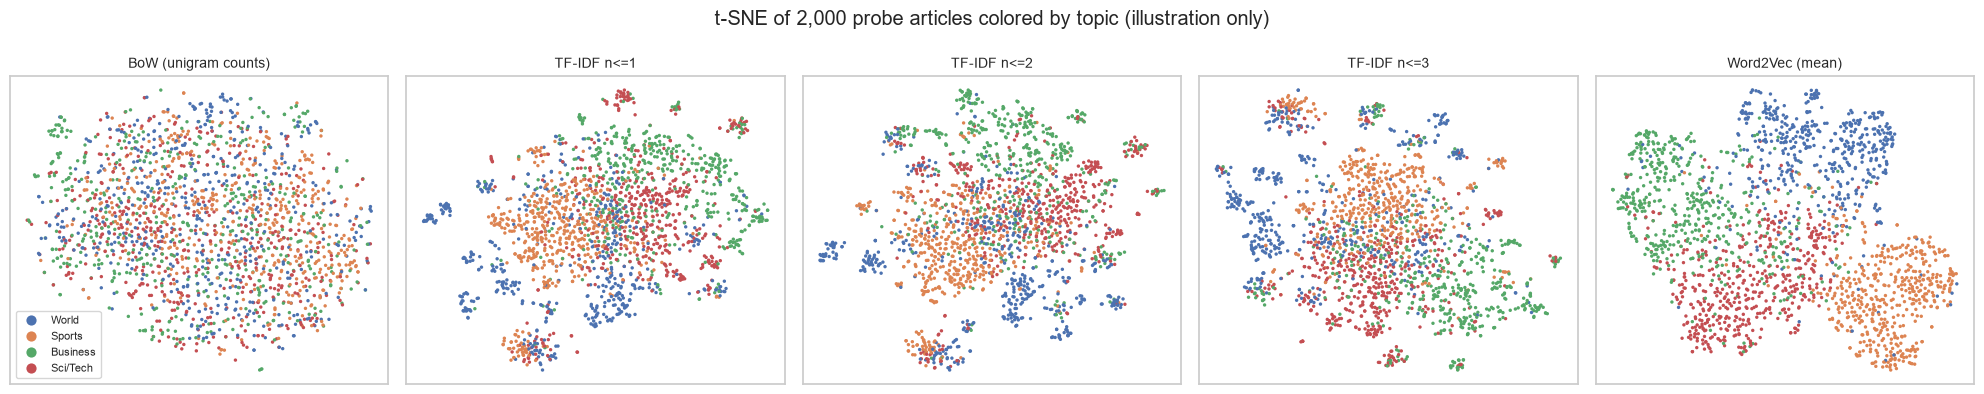

t-SNE layouts computed in 49 s


In [11]:
step_start = time.perf_counter()
tsne_layouts = {}
for name, X in probe_matrices.items():
    if hasattr(X, "tocsr"):
        # t-SNE on 50 SVD components fitted on cv_subset; the SVD fit uses no probe data.
        svd = TruncatedSVD(n_components=50, random_state=RANDOM_STATE).fit(fitted[name].transform(cv_norm))
        X = svd.transform(X)
    tsne_layouts[name] = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE, n_jobs=N_JOBS).fit_transform(X)

fig, axes = plt.subplots(1, len(tsne_layouts), figsize=(4 * len(tsne_layouts), 4))
for ax, (name, layout) in zip(axes, tsne_layouts.items()):
    sns.scatterplot(x=layout[:, 0], y=layout[:, 1], hue=probe["topic"].to_numpy(), hue_order=LABEL_ORDER, s=6, linewidth=0, ax=ax, legend=ax is axes[0])
    ax.set_title(name, fontsize=10)
    ax.set_xticks([]), ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
fig.suptitle(f"t-SNE of {len(probe):,} probe articles colored by topic (illustration only)")
plt.tight_layout()
plt.show()
print(f"t-SNE layouts computed in {time.perf_counter() - step_start:.0f} s")

In [12]:
step_start = time.perf_counter()
for name, vectorizer in representations.items():
    classifier = logistic_regression()
    SCORES_BY_NAME[f"repr: {name}"] = cv_scores(make_pipeline(vectorizer, classifier), cv_norm)
SCORES_BY_NAME["repr: Word2Vec (mean)"] = cv_scores(make_pipeline(MeanWordVectors(**W2V_SETTINGS), logistic_regression()), cv_tokens)
representation_cv = compare({name: SCORES_BY_NAME[f"repr: {name}"] for name in probe_matrices}, "TF-IDF n<=1")
print(f"Logistic regression, 5-fold CV on {len(cv_subset):,} articles ({time.perf_counter() - step_start:.0f} s)")
display(representation_cv.round(4))

Logistic regression, 5-fold CV on 30,000 articles (70 s)


,macro_f1_mean,macro_f1_std,accuracy_mean,diff_vs_baseline,diff_std,folds_better
BoW (unigram counts),0.8851,0.0029,0.8852,-0.0161,0.0019,0.0
TF-IDF n<=1,0.9012,0.0033,0.9015,0.0000,0.0000,0.0
TF-IDF n<=2,0.8994,0.0027,0.8997,-0.0018,0.0019,1.0
TF-IDF n<=3,0.8982,0.0029,0.8985,-0.0030,0.0019,1.0
Word2Vec (mean),0.8786,0.0035,0.8789,-0.0226,0.0021,0.0


BoW and TF-IDF are extremely sparse: an article has about {eval}`f"{representation_summary.loc['TF-IDF n<=1', 'mean_nonzeros_per_doc']:.0f}"` nonzero entries out of {eval}`f"{int(representation_summary.loc['TF-IDF n<=1', 'dimensions']):,}"` unigram features (sparsity {eval}`f"{representation_summary.loc['TF-IDF n<=1', 'sparsity']:.2%}"`). Adding bigrams and trigrams multiplies the dimension to {eval}`f"{int(representation_summary.loc['TF-IDF n<=3', 'dimensions']):,}"` while each article gains few nonzeros, because most n-grams occur in only a few articles. Word2Vec gives dense 100-dimensional vectors, and every probe article has at least one in-vocabulary word ({eval}`w2v_all_oov_probe` zero vectors).

The similarity measures favor Word2Vec. Same-topic TF-IDF pairs are only slightly more similar than different-topic pairs (mean cosine {eval}`f"{representation_summary.loc['TF-IDF n<=1', 'cosine_same_mean']:.4f}"` against {eval}`f"{representation_summary.loc['TF-IDF n<=1', 'cosine_different_mean']:.4f}"`), because two short articles usually share no content word at all and their cosine is 0. Averaged word vectors give every pair a high cosine ({eval}`f"{representation_summary.loc['Word2Vec (mean)', 'cosine_different_mean']:.2f}"` even across topics), since common words pull all averages toward one direction, but same-topic pairs are consistently higher (rank-biserial {eval}`f"{representation_summary.loc['Word2Vec (mean)', 'rank_biserial_same_vs_different']:.2f}"` against {eval}`f"{representation_summary.loc['TF-IDF n<=1', 'rank_biserial_same_vs_different']:.2f}"` for TF-IDF). The topic silhouette follows the same pattern: near zero for every sparse representation ({eval}`f"{representation_summary.loc['TF-IDF n<=1', 'silhouette_cosine']:.4f}"` for unigram TF-IDF) and {eval}`f"{representation_summary.loc['Word2Vec (mean)', 'silhouette_cosine']:.3f}"` for Word2Vec. The t-SNE layouts show the same contrast. Averaged Word2Vec vectors form four topic regions, with Business and Sci/Tech adjacent. The TF-IDF layouts show a mixed central mass with small tight islands, groups of articles that share rare words such as repeated stories, and BoW shows almost no structure. The layouts are illustrations; the silhouette is the measurement.

Classification reverses the ranking. Logistic regression reaches its highest cross-validated macro-F1 with unigram TF-IDF ({eval}`f"{representation_cv.loc['TF-IDF n<=1', 'macro_f1_mean']:.4f}"`), and Word2Vec is the weakest representation ({eval}`f"{representation_cv.loc['Word2Vec (mean)', 'diff_vs_baseline']:+.4f}"`). Silhouette measures whether all dimensions together place articles near their own topic; a linear classifier only needs a few topic words with large weights, which sparse features provide directly and averaging dilutes. A low silhouette therefore does not mean a representation is bad for classification. Bigrams and trigrams lower macro-F1 slightly ({eval}`f"{representation_cv.loc['TF-IDF n<=2', 'diff_vs_baseline']:+.4f}"` and {eval}`f"{representation_cv.loc['TF-IDF n<=3', 'diff_vs_baseline']:+.4f}"`): with 24,000 training articles per fold, most added n-grams are rare, and at the default regularization they add parameters faster than evidence. BoW is clearly below TF-IDF, which shows the value of IDF weighting and length normalization for linear models.

## Advanced: Compare Sentence Transformer embeddings

This section is marked advanced in the assignment and also appears in the marking rubric. A Sentence Transformer (Reimers and Gurevych, 2019) maps a whole text to a dense vector with a transformer encoder trained so that texts with similar meaning have similar vectors. The model is [`sentence-transformers/all-MiniLM-L6-v2`](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) (Apache-2.0), pinned to a commit revision: a six-layer MiniLM encoder with mean pooling over token embeddings and 384 output dimensions, fine-tuned on over one billion sentence pairs. Inputs longer than the model's limit of 256 word pieces are truncated, and the share of truncated test articles is reported. Embeddings are scaled to unit length.

The model reads the cleaned text from the tokenization section, with case and punctuation kept, because it was trained on natural text and has its own tokenizer. It is pretrained and has no state fitted on AG News, so encoding outside the cross-validation folds leaks nothing. Encoding runs on CPU in CI, which is why this comparison uses the 8,000-article `st_subset` with its own five folds; the TF-IDF baseline is scored on the same articles and folds.

Two comparisons follow the assignment. K-Means with $k = 4$ (ten initializations, seeded) clusters the probe articles in each representation; the silhouette of the cluster assignment measures how compact and separated the clusters are, and the adjusted Rand index (ARI) measures their agreement with the topics, from 0 for chance to 1 for identical partitions. A linear support vector machine (`LinearSVC`, default settings) is then cross-validated on TF-IDF features and on the embeddings. The TF-IDF variant is the n-gram range with the highest cross-validated macro-F1 in the previous section.

In [13]:
from sentence_transformers import SentenceTransformer
import torch

step_start = time.perf_counter()
ST_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
ST_REVISION = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
torch.manual_seed(RANDOM_STATE)
encoder = SentenceTransformer(ST_MODEL, revision=ST_REVISION, cache_folder=str(RAW_DATA_DIR / "huggingface"), device="cpu")
encoder.eval()


def embed(texts):
    return encoder.encode(list(texts), batch_size=64, normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)


# The encoder has no fitted state, so encoding outside the CV folds leaks nothing.
st_inputs = {"st_subset": train_clean.loc[st_subset.index], "probe": train_clean.loc[probe.index], "test": test_clean}
embeddings = {name: embed(texts) for name, texts in st_inputs.items()}
input_lengths = pd.Series([len(ids) for ids in encoder.tokenizer(st_inputs["test"].tolist())["input_ids"]])
truncated_share = float((input_lengths > encoder.max_seq_length).mean())
print(f"Model {ST_MODEL} at revision {ST_REVISION}; max_seq_length {encoder.max_seq_length}; dimension {embeddings['test'].shape[1]}")
print(f"Test inputs longer than max_seq_length (truncated): {truncated_share:.2%}; longest {input_lengths.max()} word pieces")
print(f"Encoded {sum(len(v) for v in embeddings.values()):,} articles in {time.perf_counter() - step_start:.0f} s on {torch.get_num_threads()} CPU threads")

'[WinError 10054] An existing connection was forcibly closed by the remote host' thrown while requesting GET https://huggingface.co/api/models/sentence-transformers/all-MiniLM-L6-v2/tree/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/additional_chat_templates


Retrying in 1s [Retry 1/5].


Model sentence-transformers/all-MiniLM-L6-v2 at revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41; max_seq_length 256; dimension 384
Test inputs longer than max_seq_length (truncated): 0.00%; longest 196 word pieces
Encoded 17,600 articles in 94 s on 14 CPU threads


In [14]:
step_start = time.perf_counter()
best_tfidf = max(["TF-IDF n<=1", "TF-IDF n<=2", "TF-IDF n<=3"], key=lambda n: SCORES_BY_NAME[f"repr: {n}"]["macro_f1"].mean())
tfidf_probe = probe_matrices[best_tfidf]
st_probe = embeddings["probe"]
same, different = pair_cosines(st_probe, same_pairs), pair_cosines(st_probe, different_pairs)
pair_similarity["Sentence Transformer"] = (same, different)

rows = {}
for name, X in [(best_tfidf, tfidf_probe), ("Sentence Transformer", st_probe)]:
    clusters = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE).fit_predict(X)
    rows[name] = {
        "dimensions": X.shape[1],
        "kmeans_silhouette_cosine": silhouette_score(X, clusters, metric="cosine"),
        "kmeans_ari_vs_topic": adjusted_rand_score(y_probe, clusters),
        "topic_silhouette_cosine": silhouette_score(X, y_probe, metric="cosine"),
        "cosine_gap_same_minus_different": pair_similarity[name][0].mean() - pair_similarity[name][1].mean(),
    }
clustering_comparison = pd.DataFrame(rows).T

st_text = train_norm.loc[st_subset.index]
SCORES_BY_NAME["st: TF-IDF + LinearSVC"] = cv_scores(
    make_pipeline(whitespace_tfidf(min_df=2, ngram_range=representations[best_tfidf].ngram_range), LinearSVC()), st_text, y=y_st, cv=st_folds
)
SCORES_BY_NAME["st: Sentence Transformer + LinearSVC"] = cv_scores(LinearSVC(), embeddings["st_subset"], y=y_st, cv=st_folds)
embedding_cv = compare({n: SCORES_BY_NAME[f"st: {n}"] for n in ["TF-IDF + LinearSVC", "Sentence Transformer + LinearSVC"]}, "TF-IDF + LinearSVC")
print(f"K-Means and silhouette on {len(probe):,} probe articles; LinearSVC 5-fold CV on {len(st_subset):,} st_subset articles")
print(f"TF-IDF variant: {best_tfidf} (highest CV macro-F1 above); computed in {time.perf_counter() - step_start:.0f} s")
display(clustering_comparison.round(4))
display(embedding_cv.round(4))

K-Means and silhouette on 2,000 probe articles; LinearSVC 5-fold CV on 8,000 st_subset articles
TF-IDF variant: TF-IDF n<=1 (highest CV macro-F1 above); computed in 8 s


,dimensions,kmeans_silhouette_cosine,kmeans_ari_vs_topic,topic_silhouette_cosine,cosine_gap_same_minus_different
TF-IDF n<=1,25710.0,0.0053,0.1446,0.0044,0.0057
Sentence Transformer,384.0,0.0676,0.6134,0.0552,0.0798


,macro_f1_mean,macro_f1_std,accuracy_mean,diff_vs_baseline,diff_std,folds_better
TF-IDF + LinearSVC,0.8796,0.0042,0.8800,0.0000,0.0000,0.0
Sentence Transformer + LinearSVC,0.8851,0.0078,0.8853,0.0055,0.0057,5.0


In [15]:
# Pairs where the two similarity measures disagree most, by rank within each measure.
pair_table = pd.DataFrame(
    np.vstack([same_pairs, different_pairs]), columns=["a", "b"]
).assign(
    same_topic=np.r_[np.ones(N_PAIRS, bool), np.zeros(N_PAIRS, bool)],
    tfidf=np.r_[pair_similarity[best_tfidf][0], pair_similarity[best_tfidf][1]],
    embedding=np.r_[pair_similarity["Sentence Transformer"][0], pair_similarity["Sentence Transformer"][1]],
)
pair_table["rank_gap"] = pair_table["embedding"].rank(pct=True) - pair_table["tfidf"].rank(pct=True)
similarity_rank_correlation = pair_table[["tfidf", "embedding"]].corr(method="spearman").iloc[0, 1]


def show_pairs(rows):
    texts = train_clean.loc[probe.index].to_numpy()
    topics = probe["topic"].to_numpy()
    display(pd.DataFrame({
        "tfidf": rows["tfidf"].round(3), "embedding": rows["embedding"].round(3),
        "topic a": topics[rows["a"]], "text a": [texts[i][:150] for i in rows["a"]],
        "topic b": topics[rows["b"]], "text b": [texts[i][:150] for i in rows["b"]],
    }))


print(f"Spearman correlation between TF-IDF and embedding pair similarities: {similarity_rank_correlation:.3f}")
print("Same-topic pairs that the embedding rates similar but TF-IDF does not:")
show_pairs(pair_table[pair_table["same_topic"]].nlargest(3, "rank_gap"))
print("Different-topic pairs that the embedding rates similar but TF-IDF does not:")
show_pairs(pair_table[~pair_table["same_topic"]].nlargest(3, "rank_gap"))

Spearman correlation between TF-IDF and embedding pair similarities: 0.205
Same-topic pairs that the embedding rates similar but TF-IDF does not:


,tfidf,embedding,topic a,text a,topic b,text b
86,-0.0,0.303,Sci/Tech,"Nokia combats counterfeit batteries In an effort to combat (now common) counterfeit batteries, Nokia has launched a new program that will allow consum",Sci/Tech,"Illicit Cameraphone Clicks Could Mean Jail Camera phones may make great Christmas gifts, but people better not use them for peeping-Tom photos on fede"
1397,-0.0,0.287,Sports,Baseball Today (AP) AP - San Francisco at Florida (7:05 p.m. EDT). Giants rookie Noah Lowry (3-0) starts against Dontrelle Willis (9-9).,Sports,Mauresmo Takes Over as World Number One NEW YORK (Reuters) - Amelie Mauresmo became world number one for the first time after Lindsay Davenport was de
1385,0.0,0.327,Sci/Tech,HP creating software to limit virus damage SAN FRANCISCO Engineers at Hewlett-Packard are working on what they call virus-throttling software that cou,Sci/Tech,"IBM Dominates Top Supercomputer List (PC World) PC World - Silicon Graphics comes in second for ""fast computer"" bragging rights."


Different-topic pairs that the embedding rates similar but TF-IDF does not:


,tfidf,embedding,topic a,text a,topic b,text b
3199,0.003,0.306,World,Tennis: Federer leads Agassi Roger Federer leads Andre Agassi two sets to one before rain interrupts their US Open quarter-final.,Sports,"Noguchi Reduces Radcliffe to Tears, Kastor Wins Bronze ATHENS (Reuters) - Japan's diminutive Mizuki Noguchi put on an extraordinary display of front-r"
2303,0.002,0.224,World,Tennis: Federer leads Agassi Roger Federer leads Andre Agassi two sets to one before rain interrupts their US Open quarter-final.,Sports,UPDATE 2-Gibernau beats Rossi in Czech GP revenge Spaniard Sete Gibernau cruised to his third win of the season in the Czech MotoGP Grand Prix on Sund
2791,0.000,0.206,Business,"C&W Says Sayonara to Japan UK-based Cable & Wireless, which has been selling off pieces of itself or just discontinuing business in certain world mark",Sci/Tech,PeopleSoft Forges On; Oracle App Sales Down Less than two weeks after US District Judge Vaughn Walker gave Oracle an important victory over the Justic


No test article exceeds the model's input limit ({eval}`f"{truncated_share:.1%}"` truncated), so the embeddings describe the full title and description.

The pretrained embeddings organize the articles by topic far better than TF-IDF without any training on AG News. K-Means with four clusters agrees with the topics at ARI {eval}`f"{clustering_comparison.loc['Sentence Transformer', 'kmeans_ari_vs_topic']:.2f}"` on embeddings against {eval}`f"{clustering_comparison.loc[best_tfidf, 'kmeans_ari_vs_topic']:.2f}"` on TF-IDF, and the cluster silhouette is {eval}`f"{clustering_comparison.loc['Sentence Transformer', 'kmeans_silhouette_cosine']:.3f}"` against {eval}`f"{clustering_comparison.loc[best_tfidf, 'kmeans_silhouette_cosine']:.3f}"`. Both silhouettes are low in absolute terms, so the topics are not well-separated clusters in either space; the embedding clusters are, however, mostly topics, while TF-IDF clusters follow shared words that do not align with topics.

With a supervised linear classifier the gap narrows. On the same 8,000 articles and folds, `LinearSVC` on embeddings changes macro-F1 by {eval}`f"{embedding_cv.loc['Sentence Transformer + LinearSVC', 'diff_vs_baseline']:+.4f}"` relative to TF-IDF, better on {eval}`int(embedding_cv.loc['Sentence Transformer + LinearSVC', 'folds_better'])` of 5 folds, with a fold standard deviation of the difference of {eval}`f"{embedding_cv.loc['Sentence Transformer + LinearSVC', 'diff_std']:.4f}"`. The embedding has 384 dimensions against {eval}`f"{int(clustering_comparison.loc[best_tfidf, 'dimensions']):,}"` for TF-IDF and was trained on a billion sentence pairs, so it can relate articles that share meaning but no words. TF-IDF can only use words seen in the 6,400 training articles of each fold. With more labeled data the TF-IDF model catches up, as the final evaluation shows for logistic regression trained on 30,000 articles.

The two similarity measures rank the probe pairs differently (Spearman correlation {eval}`f"{similarity_rank_correlation:.2f}"`). The same-topic pairs that the embedding rates similar and TF-IDF does not share a theme without sharing words: two phone-related Sci/Tech stories, or two different sports. The different-topic examples show the other side. A tennis report labeled World is close to Sports articles in embedding space, which is correct about the content and wrong about the label; this is the label noise the EDA found, and no representation can fix it.

## Evaluate the selected pipelines on the test split

The selected pipeline follows the rule fixed in the protocol, applied greedily to the cross-validation tables above: normalization against raw text, then wire-tag removal, stop-word removal, the best of the three stemming methods against none, and longer n-gram ranges against shorter ones. Each choice uses logistic regression results only, and the test split is not consulted.

Four pipelines are then fitted once and scored once on the 7,600 test articles: the raw-text baseline and the selected pipeline, both trained on `cv_subset`, and the TF-IDF and Sentence Transformer `LinearSVC` models from the previous section, both trained on `st_subset`. The EDA found that about one test article in nine has a training article at TF-IDF cosine similarity of 0.9 or more, so a second macro-F1 column excludes those test articles to check whether near-copies of training text drive the scores.

In [16]:
step_start = time.perf_counter()
# Greedy selection from the CV tables only; the test split is not consulted.
selection = {}
selection["normalization"] = prefer("norm: raw", "norm: full pipeline")
if selection["normalization"] == "norm: full pipeline":
    selection["wire tags"] = prefer("norm: full pipeline", "norm: full pipeline, wire tags removed")
selection["stop words"] = prefer("stop LR: keep stop words", "stop LR: remove stop words")
best_stemmer = max(["Porter", "Snowball", "WordNet (POS)"], key=lambda n: SCORES_BY_NAME[f"stem: {n}"]["macro_f1"].mean())
selection["stemming"] = prefer("stem: none", f"stem: {best_stemmer}")
selection["n-gram range"] = prefer("repr: TF-IDF n<=1", "repr: TF-IDF n<=2")
if selection["n-gram range"] == "repr: TF-IDF n<=2":
    selection["n-gram range"] = prefer("repr: TF-IDF n<=2", "repr: TF-IDF n<=3")
display(pd.Series(selection, name="selected").to_frame())

,selected
normalization,norm: full pipeline
wire tags,norm: full pipeline
stop words,stop LR: keep stop words
stemming,stem: none
n-gram range,repr: TF-IDF n<=1


In [17]:
def prepare(texts):
    # Applies the selected deterministic text steps; nothing here is fitted.
    if selection["normalization"] == "norm: raw":
        return texts.tolist()
    if selection.get("wire tags") == "norm: full pipeline, wire tags removed":
        texts = texts.map(remove_wire_tags)
    texts = texts.map(normalize)
    if selection["stemming"] != "stem: none":
        stemmer = {"stem: Porter": porter, "stem: Snowball": snowball}.get(selection["stemming"])
        if stemmer is None:
            return [" ".join(wordnet.lemmatize(t, WORDNET_POS.get(tag[0], "n")) if t.isalpha() else t for t, tag in doc)
                    for doc in nltk.pos_tag_sents([text.split() for text in texts])]
        return [" ".join(stemmer.stem(t) if t.isalpha() else t for t in text.split()) for text in texts]
    return texts.tolist()


ngram_max = int(selection["n-gram range"][-1])
stop = STOP_WORDS if selection["stop words"].endswith("remove stop words") else None
final_models = {
    "raw text, TF-IDF n<=1 + LR": (make_pipeline(whitespace_tfidf(), logistic_regression()), cv_subset["text"].tolist(), y_cv, test["text"].tolist()),
    "selected preprocessing + LR": (
        make_pipeline(whitespace_tfidf(min_df=2, ngram_range=(1, ngram_max), stop_words=stop), logistic_regression()),
        prepare(cv_subset["text"]), y_cv, prepare(test["text"]),
    ),
    "TF-IDF + LinearSVC (st_subset)": (
        make_pipeline(whitespace_tfidf(min_df=2, ngram_range=representations[best_tfidf].ngram_range), LinearSVC()),
        st_text.tolist(), y_st, test_norm.tolist(),
    ),
    "Sentence Transformer + LinearSVC (st_subset)": (LinearSVC(), embeddings["st_subset"], y_st, embeddings["test"]),
}
nearest = nearest_train_similarity(train, test)
NEAR_DUPLICATE_COSINE = 0.9
without_near_duplicate = (nearest["cosine"] < NEAR_DUPLICATE_COSINE).to_numpy()

rows, per_class = {}, {}
for name, (model, X_fit, y_fit, X_test) in final_models.items():
    predicted = model.fit(X_fit, y_fit).predict(X_test)
    rows[name] = {
        "train_articles": len(y_fit),
        "test_accuracy": accuracy_score(y_test, predicted),
        "test_macro_f1": f1_score(y_test, predicted, average="macro"),
        "macro_f1_without_near_duplicates": f1_score(y_test[without_near_duplicate], predicted[without_near_duplicate], average="macro"),
    }
    per_class[name] = pd.Series(f1_score(y_test, predicted, average=None), index=LABEL_ORDER)
final_results = pd.DataFrame(rows).T
final_per_class_f1 = pd.DataFrame(per_class).T
print(f"Test articles: {len(test):,}; without a training neighbor at cosine >= {NEAR_DUPLICATE_COSINE}: {int(without_near_duplicate.sum()):,}")
display(final_results.round(4))
display(final_per_class_f1.round(4))
print(f"Final evaluation took {time.perf_counter() - step_start:.0f} s; whole notebook {time.perf_counter() - notebook_start:.0f} s")

Test articles: 7,600; without a training neighbor at cosine >= 0.9: 6,738


,train_articles,test_accuracy,test_macro_f1,macro_f1_without_near_duplicates
"raw text, TF-IDF n<=1 + LR",30000.0,0.8950,0.8946,0.8940
selected preprocessing + LR,30000.0,0.8987,0.8984,0.8974
TF-IDF + LinearSVC (st_subset),8000.0,0.8789,0.8785,0.8764
Sentence Transformer + LinearSVC (st_subset),8000.0,0.8879,0.8877,0.8857


,World,Sports,Business,Sci/Tech
"raw text, TF-IDF n<=1 + LR",0.9007,0.9493,0.8616,0.8668
selected preprocessing + LR,0.9048,0.9555,0.8616,0.8716
TF-IDF + LinearSVC (st_subset),0.8910,0.9411,0.8361,0.8459
Sentence Transformer + LinearSVC (st_subset),0.8889,0.9597,0.8473,0.8548


Final evaluation took 25 s; whole notebook 485 s


The cross-validation tables select the full normalization pipeline, keep the wire tags and stop words, apply no stemming, and use unigram TF-IDF (`selection`). Wire-tag removal lost score, and every other candidate's mean gain was smaller than its fold-to-fold variation.

On the test split the selected pipeline reaches macro-F1 {eval}`f"{final_results.loc['selected preprocessing + LR', 'test_macro_f1']:.4f}"` against {eval}`f"{final_results.loc['raw text, TF-IDF n<=1 + LR', 'test_macro_f1']:.4f}"` for raw text, a gain of {eval}`f"{final_results.loc['selected preprocessing + LR', 'test_macro_f1'] - final_results.loc['raw text, TF-IDF n<=1 + LR', 'test_macro_f1']:+.4f}"` against {eval}`f"{normalization_cv.loc['full pipeline', 'diff_vs_baseline']:+.4f}"` in cross-validation. The direction holds on unseen articles; the size is smaller, partly because the selected pipeline also drops terms seen in only one training article (`min_df=2`). The Sentence Transformer model reaches {eval}`f"{final_results.loc['Sentence Transformer + LinearSVC (st_subset)', 'test_macro_f1']:.4f}"` against {eval}`f"{final_results.loc['TF-IDF + LinearSVC (st_subset)', 'test_macro_f1']:.4f}"` for TF-IDF trained on the same 8,000 articles, confirming the cross-validated advantage of embeddings at that training size. The Business and Sci/Tech classes have the lowest F1 for every model (`final_per_class_f1`), the boundary where the EDA found most near-duplicate label conflicts.

Excluding the {eval}`f"{len(test) - int(without_near_duplicate.sum()):,}"` test articles with a near-copy in training lowers each macro-F1 by at most {eval}`f"{(final_results['test_macro_f1'] - final_results['macro_f1_without_near_duplicates']).max():.4f}"`, so near-duplicates do not explain the scores. Each test score comes from one fitted model on one split; differences of a few thousandths between the four pipelines are within the variation seen across folds and should not be ranked more finely than the cross-validation tables allow.

## Summary

- Normalization: the full pipeline is the only step with a clear gain. Entity repair changes {eval}`f"{normalization_effects.loc['repair entities', 'docs_changed_share']:.0%}"` of articles, and the full pipeline leaves {eval}`f"{normalization_effects.loc['collapse whitespace', 'types_vs_raw']:.0%}"` of the raw vocabulary. Lowercasing and removing digits and symbols give the classification gain; markup cleanup alone does not, because link fragments were topic cues, and removing agency markers costs score because the source predicts the topic.
- Tokenization: word-level OOV on the test split is {eval}`f"{tokenization_comparison.loc['word (NLTK)', 'test_oov_token_rate']:.1%}"` of tokens but {eval}`f"{tokenization_comparison.loc['word (NLTK)', 'test_oov_type_rate']:.0%}"` of types; characters and BPE have no unknown units, and sentence-level OOV measures repeated sentences rather than coverage.
- Stop words: removal cuts {eval}`f"{1 - stop_word_summary.loc['remove stop words', 'tokens'] / stop_word_summary.loc['keep stop words', 'tokens']:.0%}"` of tokens, leaves mean MI about the same, helps Naive Bayes, and does not measurably help logistic regression; some stop words, such as `its` and `his`, are strong topic indicators.
- Stemming and lemmatization: stemmers merge {eval}`f"{collision_table.loc['Porter', 'collision_rate']:.0%}"` of word types, including unrelated words, and none of the three methods changes classification beyond fold noise at this training size.
- Representations: Word2Vec and Sentence Transformer embeddings separate topics far better by silhouette and clustering, but unigram TF-IDF with logistic regression is the strongest classifier when 30,000 labeled articles are available. Embeddings are ahead at 8,000 articles.

The [discussion chapter](report.md) relates these results to the time-series findings and states the limitations of the protocol.